In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import joblib
import os

sns.set_theme(style="whitegrid")

In [54]:
df = pd.read_csv("dataset/GiveMeSomeCredit_training.csv", index_col = 0)
df.shape
df.info()
df['SeriousDlqin2yrs'].value_counts(normalize=True)*100

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

SeriousDlqin2yrs
0    93.316
1     6.684
Name: proportion, dtype: float64

In [55]:
df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


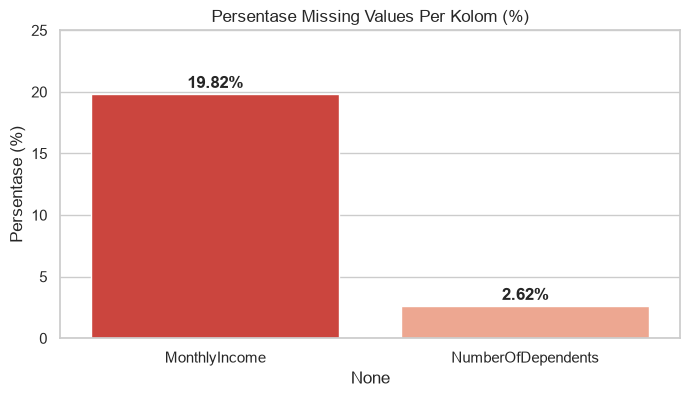

In [56]:
missing_data = df.isnull().sum()
missing_percent = (missing_data/len(df))*100

missing_df = pd.DataFrame({
    'Total Missing': missing_data,
    'Percentage (%)': missing_percent
}).query('`Total Missing` > 0')

plt.figure(figsize=(8, 4))
sns.barplot(
    x=missing_df.index, 
    y=missing_df['Percentage (%)'], 
    hue=missing_df.index, 
    palette='Reds_r', 
    legend=False
)
plt.title('Persentase Missing Values Per Kolom (%)', fontsize=12)
plt.ylabel('Persentase (%)')
plt.ylim(0,25)

for index, value in enumerate(missing_df['Percentage (%)']):
    plt.text(index, value + 0.5, f"{value:.2f}%", ha='center', fontweight='bold')
    
plt.show()

In [57]:
df_clean = df.copy()
df_clean = df_clean[df_clean['age'] > 0]
median_income = df_clean['MonthlyIncome'].median()
df_clean['MonthlyIncome'] = df_clean['MonthlyIncome'].fillna(median_income)
df_clean['NumberOfDependents'] = df_clean['NumberOfDependents'].fillna(0)

print('Jumlah missing value setelah diisi : ',df_clean.isnull().sum().sum())

Jumlah missing value setelah diisi :  0


In [58]:
df_clean['TotalPastDue'] = (
    df_clean['NumberOfTime30-59DaysPastDueNotWorse'] 
    + df_clean['NumberOfTime60-89DaysPastDueNotWorse'] 
    + df_clean['NumberOfTimes90DaysLate']
) 
df_clean[["NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfTimes90DaysLate", "TotalPastDue"]].head()

df_clean['MonthlyDebt'] = df_clean['MonthlyIncome'] * df_clean['DebtRatio']

df_clean.head(5)

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,TotalPastDue,MonthlyDebt
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0,2,7323.197016
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0,0,316.878123
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0,2,258.914887
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0,0,118.963951
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0,1,1584.975094


In [59]:
X = df_clean.drop(columns=['SeriousDlqin2yrs'])
y = df_clean['SeriousDlqin2yrs']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify = y, random_state = 42)
print('Ukuran X_train)', X_train.shape)
print('Ukuran X_test)', X_test.shape)

Ukuran X_train) (119999, 12)
Ukuran X_test) (30000, 12)


In [60]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_model = LogisticRegression(random_state=42, max_iter = 1000)

log_model.fit(X_train_scaled, y_train)

print("Training Logistic Regression Selesai!")

Training Logistic Regression Selesai!


In [61]:
y_pred = log_model.predict(X_test_scaled)

y_pred_proba = log_model.predict_proba(X_test_scaled)[:, 1]

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print('ROC AUC Score :', roc_auc_score(y_test, y_pred_proba))

[[27934    61]
 [ 1915    90]]
              precision    recall  f1-score   support

           0       0.94      1.00      0.97     27995
           1       0.60      0.04      0.08      2005

    accuracy                           0.93     30000
   macro avg       0.77      0.52      0.52     30000
weighted avg       0.91      0.93      0.91     30000

ROC AUC Score : 0.712886572637882


In [62]:
log_balanced = LogisticRegression(class_weight='balanced', random_state=42, max_iter = 1000)
log_balanced.fit(X_train_scaled, y_train)

y_pred_bal = log_balanced.predict(X_test_scaled)
y_pred_prob_bal = log_balanced.predict_proba(X_test_scaled)[:,1]

print(confusion_matrix(y_test, y_pred_bal))
print(classification_report(y_test, y_pred_bal))
print('ROC AUC Score :',roc_auc_score (y_test, y_pred_prob_bal))

[[21767  6228]
 [  654  1351]]
              precision    recall  f1-score   support

           0       0.97      0.78      0.86     27995
           1       0.18      0.67      0.28      2005

    accuracy                           0.77     30000
   macro avg       0.57      0.73      0.57     30000
weighted avg       0.92      0.77      0.82     30000

ROC AUC Score : 0.8002411278465739


In [63]:
from xgboost import XGBClassifier

ratio = (len(y_train) - sum(y_train)) / sum(y_train)

xgb_model = XGBClassifier(scale_pos_weight=ratio, random_state=42, eval_metric='logloss')

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)
y_pred_proba_xgb = xgb_model.predict_proba(X_test)[:,1]

print(confusion_matrix(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))
print('ROC AUC Score:', roc_auc_score(y_test, y_pred_proba_xgb))

[[23334  4661]
 [  570  1435]]
              precision    recall  f1-score   support

           0       0.98      0.83      0.90     27995
           1       0.24      0.72      0.35      2005

    accuracy                           0.83     30000
   macro avg       0.61      0.77      0.63     30000
weighted avg       0.93      0.83      0.86     30000

ROC AUC Score: 0.8535413653756304


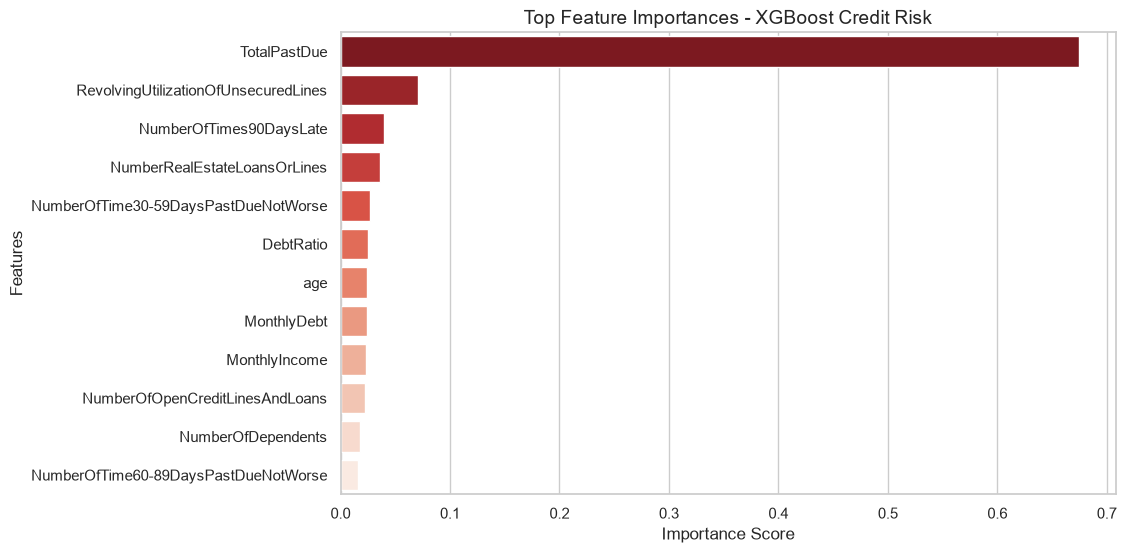

In [64]:
feature_imp = pd.DataFrame({
    'Feature' : X_train.columns,
    'Importance': xgb_model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance', 
    y='Feature', 
    data=feature_imp, 
    palette='Reds_r',
    hue='Feature',
    legend=False
)

plt.title('Top Feature Importances - XGBoost Credit Risk', fontsize=14)
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show() 

In [65]:
os.makedirs('models', exist_ok=True)
joblib.dump(xgb_model, 'models/xgb_credit_model.pkl')
print('Model XGBoost berhasil disimpan!')

Model XGBoost berhasil disimpan!
